❌ No GPU available.

🔁 Iteration 1
⚠️ Not enough uncertain samples of target class.


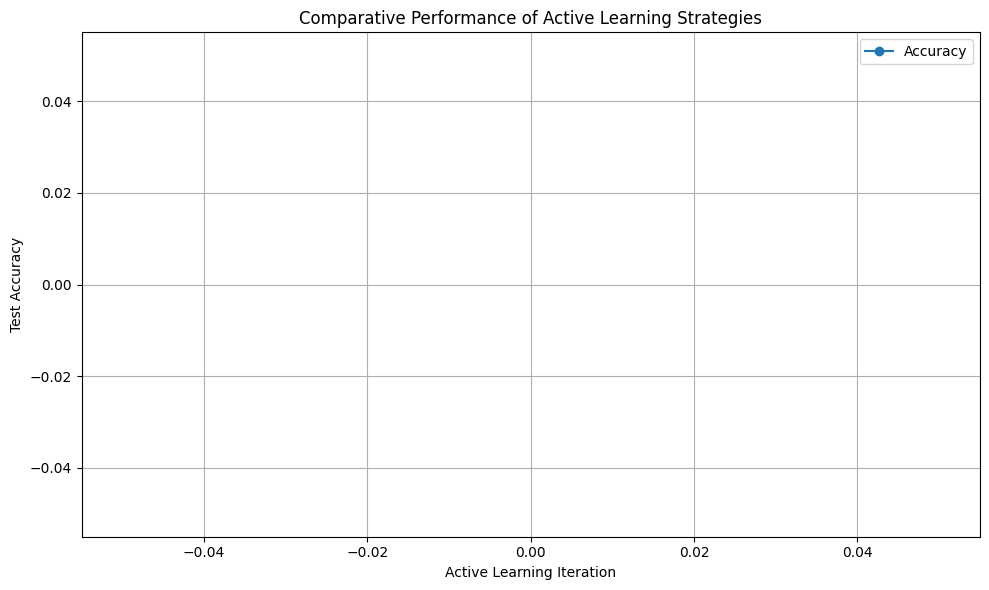

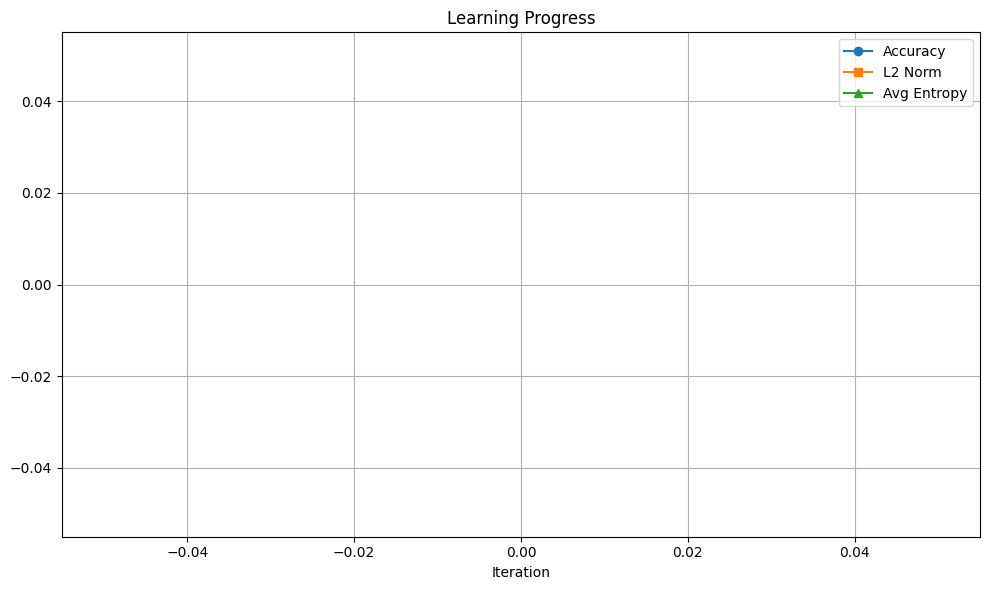

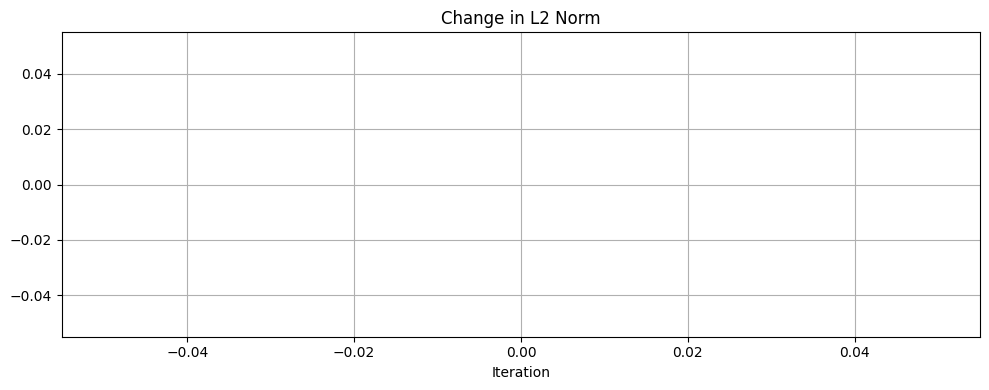

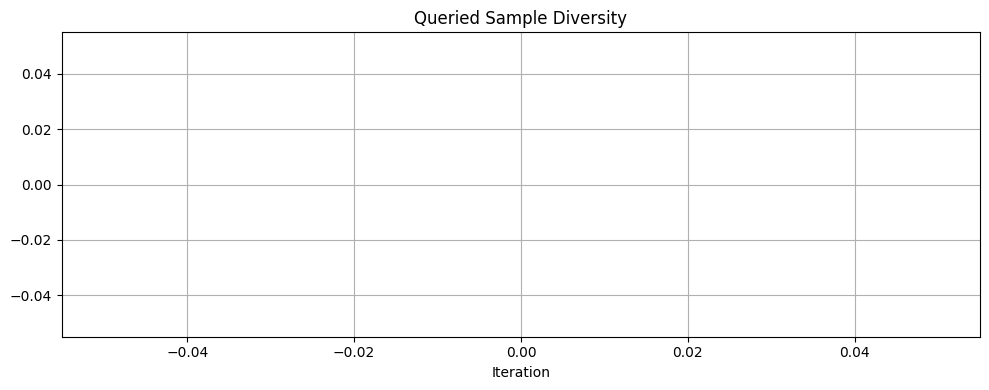

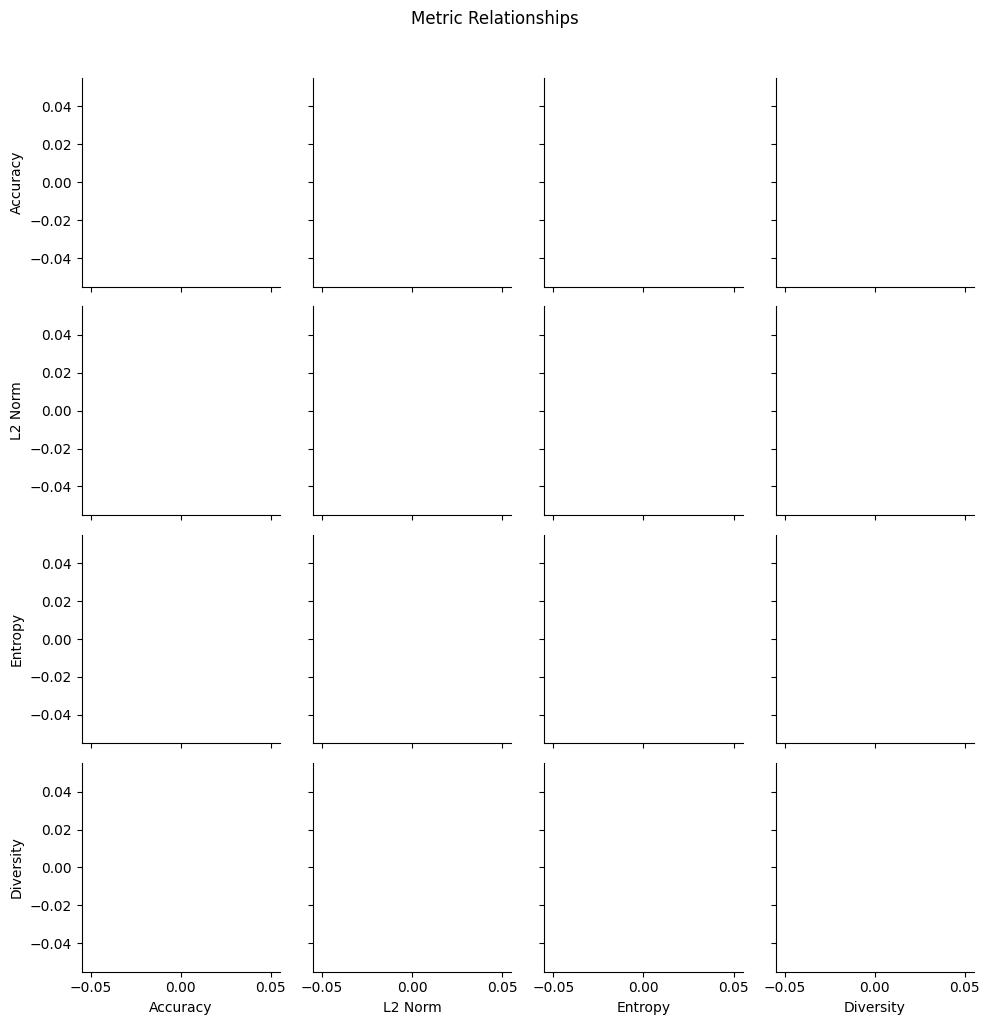

<Figure size 640x480 with 0 Axes>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# GPU config
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    try:
        tf.config.experimental.set_memory_growth(physical_devices[0], True)
        print("✅ GPU memory growth enabled.")
    except Exception as e:
        print(f"⚠️ Could not set GPU memory growth: {e}")
else:
    print("❌ No GPU available.")

# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Filter to target class
TARGET_CLASS = 3

# Binarize labels: 1 if target class, else 0
y_train = (y_train == TARGET_CLASS).astype(np.int32)
y_test = (y_test == TARGET_CLASS).astype(np.int32)


def create_cnn_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        tf.keras.layers.MaxPooling2D(2,2),
        tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2,2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']) 
    return model

np.random.seed(42)
initial_labeled_samples = 1000
query_batch_size = 500
num_iterations = 15
epochs_per_round = 10

accuracies = []
l2_norms = []
avg_query_entropy = []
query_diversity = []
l2_deltas = []

labeled_indices = np.random.choice(len(x_train), initial_labeled_samples, replace=False)
unlabeled_indices = np.setdiff1d(np.arange(len(x_train)), labeled_indices)
x_labeled, y_labeled = x_train[labeled_indices], y_train[labeled_indices]
x_unlabeled, y_unlabeled = x_train[unlabeled_indices], y_train[unlabeled_indices]

model = create_cnn_model()
model.fit(x_labeled, y_labeled, epochs=epochs_per_round, verbose=0)
l2_last = 0

for i in range(num_iterations):
    print(f"\n🔁 Iteration {i+1}")
    predictions = model.predict(x_unlabeled, verbose=0)
    uncertainty_scores = -np.sum(predictions * np.log(predictions + 1e-10), axis=1)

    class_mask = (np.argmax(predictions, axis=1) == TARGET_CLASS)
    candidate_indices = np.where(class_mask)[0]

    if len(candidate_indices) < query_batch_size:
        print("⚠️ Not enough uncertain samples of target class.")
        break

    selected = candidate_indices[np.argsort(uncertainty_scores[candidate_indices])[-query_batch_size:]]

    # Track average entropy
    query_entropies = uncertainty_scores[selected]
    avg_query_entropy.append(np.mean(query_entropies))

    # Track diversity
    x_q = x_unlabeled[selected].reshape(len(selected), -1)
    x_l = x_labeled.reshape(len(x_labeled), -1)
    avg_dist = np.mean([np.linalg.norm(xq - np.mean(x_l, axis=0)) for xq in x_q])
    query_diversity.append(avg_dist)

    # Update datasets
    new_labeled_indices = unlabeled_indices[selected]
    x_labeled = np.concatenate((x_labeled, x_unlabeled[selected]), axis=0)
    y_labeled = np.concatenate((y_labeled, y_unlabeled[selected]), axis=0)
    unlabeled_indices = np.setdiff1d(unlabeled_indices, new_labeled_indices)
    x_unlabeled, y_unlabeled = x_train[unlabeled_indices], y_train[unlabeled_indices]

    model = create_cnn_model()
    model.fit(x_labeled, y_labeled, epochs=epochs_per_round, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    l2 = np.sqrt(sum(tf.reduce_sum(tf.square(w)).numpy() for w in model.trainable_weights))

    l2_norms.append(l2)
    l2_deltas.append(l2 - l2_last)
    l2_last = l2
    accuracies.append(test_acc)

    print(f"✅ Accuracy: {test_acc:.4f} | L2 Norm: {l2:.2f} | Avg Entropy: {avg_query_entropy[-1]:.4f} | Diversity: {avg_dist:.2f}")

# --- PLOTS ---
iterations = list(range(1, len(accuracies)+1))

plt.figure(figsize=(10, 6))
plt.plot(iterations, accuracies, marker='o', label='Accuracy')
plt.xlabel('Active Learning Iteration')
plt.ylabel('Test Accuracy')
plt.title('Comparative Performance of Active Learning Strategies')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(iterations, accuracies, marker='o', label='Accuracy')
plt.plot(iterations, l2_norms, marker='s', label='L2 Norm')
plt.plot(iterations, avg_query_entropy, marker='^', label='Avg Entropy')
plt.xlabel('Iteration')
plt.title('Learning Progress')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(iterations, l2_deltas, marker='x', label='Δ L2 Norm')
plt.xlabel('Iteration')
plt.title('Change in L2 Norm')
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(iterations, query_diversity, marker='v', color='orange', label='Query Diversity')
plt.xlabel('Iteration')
plt.title('Queried Sample Diversity')
plt.grid()
plt.tight_layout()
plt.show()

# Create a DataFrame from the metrics
metrics_df = pd.DataFrame({
    'Accuracy': accuracies,
    'L2 Norm': l2_norms,
    'Entropy': avg_query_entropy,
    'Diversity': query_diversity
})

# Plot pairwise relationships
sns.pairplot(metrics_df, kind='reg')
plt.suptitle('Metric Relationships', y=1.02)
plt.tight_layout()
plt.show()

plt.suptitle('Metric Relationships')
plt.tight_layout()
plt.show()
